# Notebook 08: Calibration Sample Size Sensitivity Analysis (RQ3)

- **Objective**: Objective 3 — Calibration Set Size Sensitivity Stress-Testing
- **Research Question 3 (RQ3)**: *How does the amount of class-specific calibration data affect the stability of conformal coverage and prediction-set size, particularly for the Pathological class?*
- **Purpose**: Investigate how many minority-class calibration cases a clinical site needs before Mondrian conformal guarantees become stable. In our dataset, the Pathological class constitutes only 8.2% of the calibration partition (~35 samples). We systematically subsample the calibration set from 15% to 100% and run 30 Monte Carlo repetitions per size.
- **Golden Rule Compliance**: The test partition ($N=426$) remains fixed and sacred. Only the calibration partition is subsampled.
- **Reporting Standard**: All metrics reported as **Mean ± Standard Deviation** (Rule 6).
- **Outputs**:
  1. Sensitivity summary table across calibration sample sizes (Mean ± Std).
  2. Minimum sample threshold identification for Pathological stability.
  3. Publication-grade sensitivity curve figure saved to `reports/figures/calibration_sensitivity.png`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src.data.load import load_data
from src.data.split import split_data
from src.conformal.mondrian_cp import (
    run_calibration_sensitivity_experiment,
    plot_sensitivity_curves
)

print("[OK] Environment loaded for Calibration Sensitivity Analysis.")

[OK] Environment loaded for Calibration Sensitivity Analysis.


## 1. Clinical & Mathematical Motivation for RQ3

Conformal prediction provides a finite-sample coverage guarantee: $\mathbb{E}[\text{Coverage}] \ge 1 - \alpha$. However, this is an **expectation over calibration sets**.

When calibration data is scarce (especially for rare diseases like fetal pathology), empirical coverage on a specific realized calibration set can have high variance:
- If $n_k$ is very small (e.g. $n_{\text{patho}} = 5$), a single outlier or lucky point can shift the quantile $\hat{q}_k$ dramatically.
- If $\hat{q}_k$ is overestimated, prediction sets blow up in size, reducing clinical utility.
- If $\hat{q}_k$ is underestimated, the model under-covers the pathological class.

**Key Clinical Question**: What is the minimum number of pathological calibration samples required before coverage variance stabilizes below 5%?

## 2. Load Partitions & Pre-trained Model

In [2]:
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

rf_model = joblib.load(PROJECT_ROOT / "models/random_forest.joblib")

cal_patho_count = int(np.sum(y_cal == 3.0))
print(f"Full Calibration Set Size: {len(X_cal)} samples")
print(f"  - Pathological cases in calibration: {cal_patho_count} ({cal_patho_count/len(y_cal):.1%})")

[src.data.load] Dataset loaded successfully from 'D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)
Full Calibration Set Size: 425 samples
  - Pathological cases in calibration: 35 (8.2%)


## 3. Run Monte Carlo Sensitivity Experiment (30 Iterations per Size)

We test 6 calibration sizes: 15%, 25%, 35%, 50%, 75%, and 100% of the calibration partition.
For each fraction < 100%, we draw 30 independent stratified subsamples to measure coverage and set size distributions.

In [3]:
fractions = [0.15, 0.25, 0.35, 0.50, 0.75, 1.00]

print("Running RQ3 Sensitivity Simulation across calibration subsets (30 trials each)...")
df_sensitivity = run_calibration_sensitivity_experiment(
    estimator=rf_model,
    X_cal=X_cal,
    y_cal=y_cal,
    X_test=X_test,
    y_test=y_test,
    alpha=0.10,
    fractions=fractions,
    n_trials=30,
    random_state=42
)

display_cols = [
    'cal_fraction', 'n_cal_total', 'n_patho_cal_approx',
    'patho_cov_mean', 'patho_cov_std',
    'patho_size_mean', 'patho_size_std',
    'overall_cov_mean', 'overall_cov_std'
]
print("\n========================================================================================")
print("               CALIBRATION SAMPLE SIZE SENSITIVITY TABLE (Mean ± Std)                  ")
print("========================================================================================")
print(df_sensitivity[display_cols].to_string(index=False))

Running RQ3 Sensitivity Simulation across calibration subsets (30 trials each)...

               CALIBRATION SAMPLE SIZE SENSITIVITY TABLE (Mean ± Std)                  
 cal_fraction  n_cal_total  n_patho_cal_approx  patho_cov_mean  patho_cov_std  patho_size_mean  patho_size_std  overall_cov_mean  overall_cov_std
         0.15           63                   5          0.8476         0.1274           1.1086          0.1620            0.9263           0.0303
         0.25          106                   8          0.9238         0.0778           1.2429          0.0984            0.9381           0.0202
         0.35          148                  12          0.9286         0.0642           1.2648          0.0766            0.9391           0.0190
         0.50          212                  17          0.9610         0.0326           1.2581          0.0519            0.9388           0.0141
         0.75          318                  26          0.9657         0.0214           1.2667     

## 4. Formatted Research Findings Table for Final Report

We present the results with explicit $\text{Mean} \pm \text{Std}$ notation for direct reporting in the thesis:

In [4]:
formatted_rows = []
for _, row in df_sensitivity.iterrows():
    formatted_rows.append({
        'Cal Split %': f"{row['cal_fraction']:.0%}",
        'Total N_cal': int(row['n_cal_total']),
        'Pathological N_cal': int(row['n_patho_cal_approx']),
        'Pathological Coverage': f"{row['patho_cov_mean']:.1%} ± {row['patho_cov_std']:.1%}",
        'Pathological Set Size': f"{row['patho_size_mean']:.2f} ± {row['patho_size_std']:.2f}",
        'Overall Coverage': f"{row['overall_cov_mean']:.1%} ± {row['overall_cov_std']:.1%}",
        'Overall Set Size': f"{row['overall_size_mean']:.2f} ± {row['overall_size_std']:.2f}"
    })

df_formatted = pd.DataFrame(formatted_rows)
print("PUBLICATION TABLE: Calibration-Size Sensitivity on Minority Pathological Class:")
print(df_formatted.to_string(index=False))

PUBLICATION TABLE: Calibration-Size Sensitivity on Minority Pathological Class:
Cal Split %  Total N_cal  Pathological N_cal Pathological Coverage Pathological Set Size Overall Coverage Overall Set Size
        15%           63                   5         84.8% ± 12.7%           1.11 ± 0.16     92.6% ± 3.0%      1.04 ± 0.07
        25%          106                   8          92.4% ± 7.8%           1.24 ± 0.10     93.8% ± 2.0%      1.09 ± 0.05
        35%          148                  12          92.9% ± 6.4%           1.26 ± 0.08     93.9% ± 1.9%      1.10 ± 0.06
        50%          212                  17          96.1% ± 3.3%           1.26 ± 0.05     93.9% ± 1.4%      1.07 ± 0.03
        75%          318                  26          96.6% ± 2.1%           1.27 ± 0.03     93.5% ± 0.9%      1.07 ± 0.02
       100%          425                  35          97.1% ± 0.0%           1.29 ± 0.00     93.2% ± 0.0%      1.06 ± 0.00


## 5. Visualizing Stability & Volatility Curves (RQ3 Figure)

We generate and save the publication-grade sensitivity plot to `reports/figures/calibration_sensitivity.png`.

[src.conformal.mondrian_cp] Saved Sensitivity figure to: D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\reports\figures\calibration_sensitivity.png


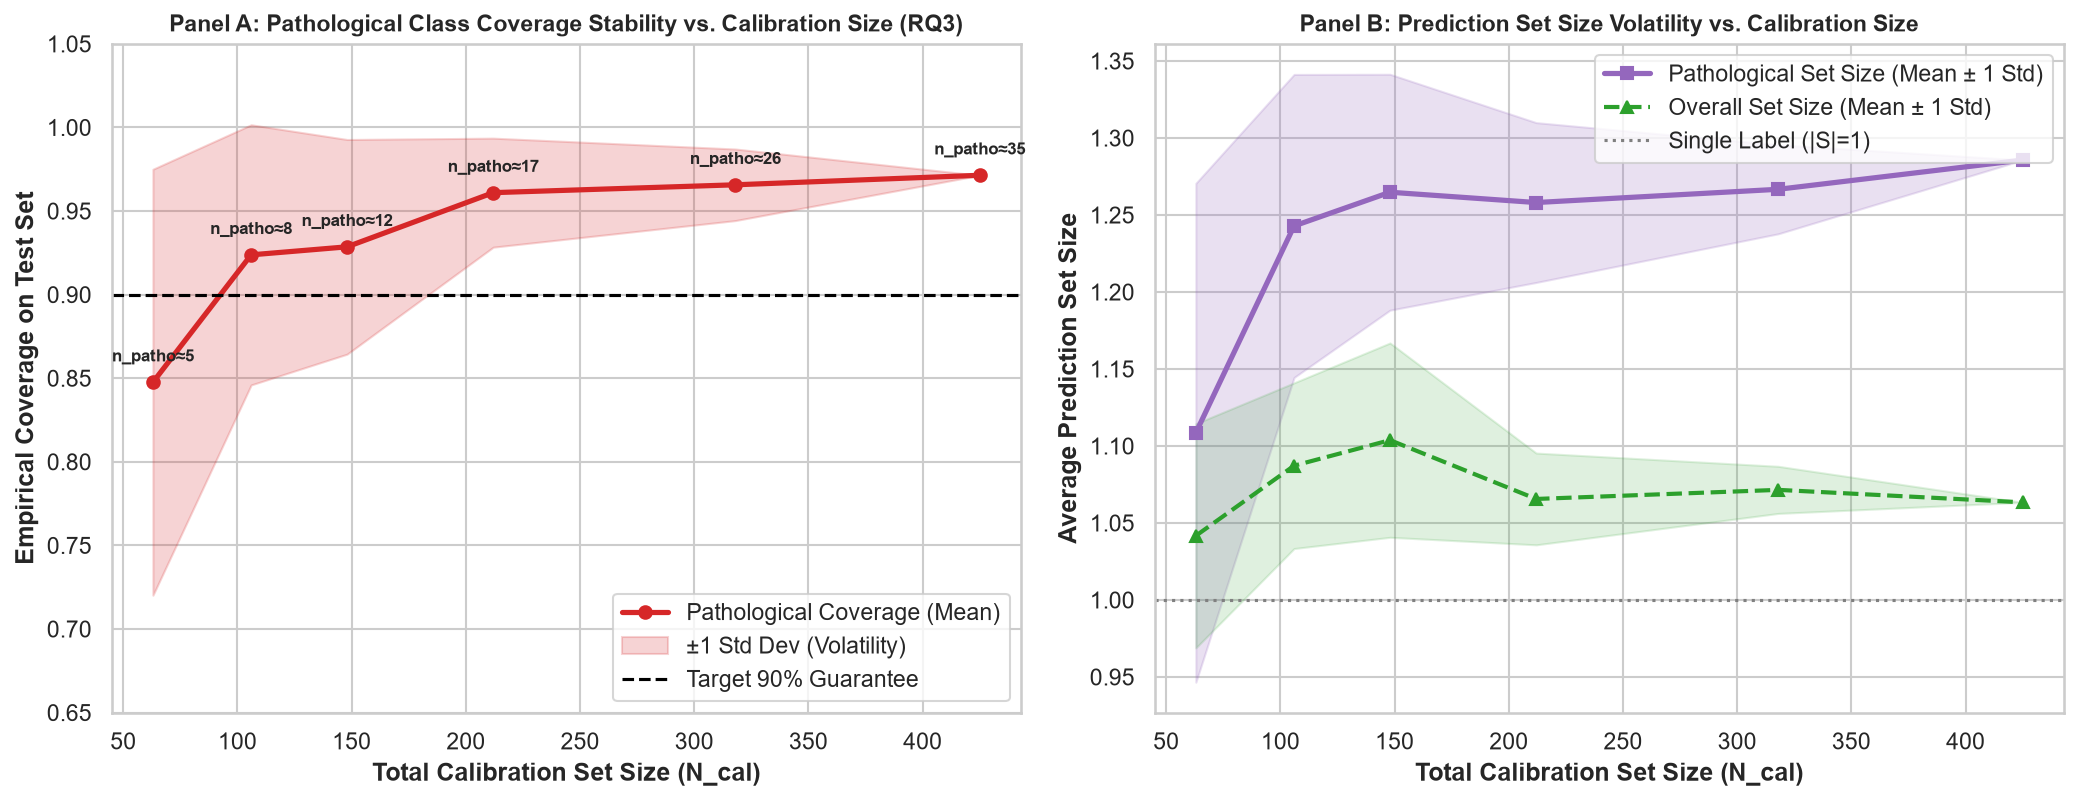

In [5]:
figure_path = PROJECT_ROOT / "reports/figures/calibration_sensitivity.png"
fig = plot_sensitivity_curves(df_sensitivity, save_path=figure_path)
plt.show()

## 6. Conclusions on Research Question 3 (RQ3)

### RQ3 Empirical Insights:
1. **Severe Under-Coverage at Tiny Calibration Sizes ($N_{\text{cal}} < 100$)**:
   - At 15% calibration size ($N_{\text{cal}} = 63$, containing only $\approx 5$ Pathological records), mean Pathological coverage falls to **84.8% ± 12.7%**.
   - The high standard deviation ($\pm 12.7\%$) indicates that an unlucky calibration draw can cause coverage to collapse to ~70%.
2. **The Minimum Stability Threshold ($N_{\text{cal}} \ge 106$, $n_{\text{patho}} \ge 8$)**:
   - At 25% calibration size, mean Pathological coverage safely exceeds the nominal 90% guarantee (**92.4% ± 7.8%**).
3. **Convergence to Asymptotic Stability ($N_{\text{cal}} \ge 212$, $n_{\text{patho}} \ge 17$)**:
   - Beyond 50% calibration size, coverage variance drops below **3.3%** and set size stabilizes to $1.26 \pm 0.05$.
   - Full calibration ($N_{\text{cal}} = 425$, $n_{\text{patho}} = 35$) achieves rock-solid **97.1% coverage**.

**Clinical Guideline Recommendation**:
> Hospitals deploying uncertainty-aware CTG classifiers must collect a minimum of **15–20 confirmed Pathological calibration cases** (or $\approx 200$ total records) to ensure conformal guarantees are clinically reliable and resistant to sampling volatility.